# BERTopic: from individual algorithms to a complete topic model
**Data Mining · Lorenzo Mannocci**


Run in order in Jupyter or Google Colab. Internet is needed on the first run to install packages and download 20 Newsgroups and a pretrained encoder. CPU execution is supported; embedding and the first UMAP fit may take several minutes. The default uses at most 1,800 documents. Cached embeddings avoid repeated encoding.


In [38]:
# Run once in a fresh environment. Restart the kernel if an existing installation requires it.
# %pip install -q "bertopic>=0.16,<0.18" "sentence-transformers>=3,<6" "umap-learn>=0.5.7,<0.6" "hdbscan>=0.8.40,<0.9" "scikit-learn>=1.4,<2" pandas matplotlib seaborn plotly ipywidgets

In [39]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import hashlib, json, re
import numpy as np
import pandas as pd
import copy 
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse
from sklearn.datasets import fetch_20newsgroups
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN

SEED = 42
N_PER_CATEGORY = 300       # Try 100 for a shorter demonstration.
RUN_EXTENDED_SWEEPS = False
CACHE = Path('bertopic_demo_cache')
CACHE.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110})
packages = ['bertopic', 'sentence-transformers', 'umap-learn', 'hdbscan', 'scikit-learn']
display(pd.DataFrame({'package': packages, 'version': [version(p) for p in packages]}))

,package,version
0,bertopic,0.17.4
1,sentence-transformers,5.7.0
2,umap-learn,0.5.7
3,hdbscan,0.8.44
4,scikit-learn,1.7.1


## 1. Corpus: six discussion categories
We use six categories with some overlap: two sports, two computing categories, space, and medicine. Labels are retained **only for retrospective inspection**, never supplied to the encoder, UMAP, HDBSCAN, or BERTopic.

Discussion categories are not ground-truth topics: a category may contain several themes, and themes can cross categories. We sample deterministically after removing empty/very short texts and duplicates.

### Download or read file

In [40]:
# Optional: set a CSV path with a text column and an optional category column.
# With no categories, all rows receive 'unlabeled'; external-label scores are then uninformative.
LOCAL_CSV = None
categories = ['rec.sport.baseball', 'rec.sport.hockey', 'comp.graphics',
              'comp.sys.mac.hardware', 'sci.space', 'sci.med']
if LOCAL_CSV is None:
    raw = fetch_20newsgroups(subset='train', categories=categories,
                             remove=('headers', 'footers', 'quotes'),
                             shuffle=True, random_state=SEED)
    corpus = pd.DataFrame({'text': raw.data,
                           'category': [raw.target_names[t] for t in raw.target]})
else:
    corpus = pd.read_csv(LOCAL_CSV)

    corpus = corpus.dropna(subset=['text']).copy()
    corpus['text'] = corpus.text.astype(str)
    corpus['category'] = corpus.category.fillna('unlabeled').astype(str)

### Preprocessing

In [41]:
# Replace consecutive whitespace characters (spaces, tabs, newlines)
# with a single space, then remove leading and trailing whitespace.
corpus['text'] = corpus['text'].map(lambda s: re.sub(r'\s+', ' ', s).strip())

# Keep documents with at least 20 whitespace-separated words.
# Remove duplicate texts, retaining the first occurrence.
corpus = corpus[corpus['text'].str.split().str.len() >= 20].drop_duplicates('text')

# Randomly select up to N_PER_CATEGORY documents from each category.
# If a category contains fewer documents, keep all of them.
# SEED makes the sampling reproducible.
# Concatenate the samples and create a new consecutive index.
corpus = pd.concat(
    [
        g.sample(n=min(N_PER_CATEGORY, len(g)), random_state=SEED)
        for _, g in corpus.groupby('category')
    ],
    ignore_index=True
)

# Shuffle all selected documents so they are no longer grouped by category.
# frac=1 retains every row; reset_index removes the previous row indices.
corpus = corpus.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Convert the text column into a Python list: the input documents.
docs = corpus['text'].tolist()

# Store the corresponding category labels as a NumPy array.
# These labels are used only for evaluating/interpreting the results,
# not for training the unsupervised pipeline.
y_reference = corpus['category'].to_numpy()



print(f'{len(docs):,} documents; {corpus['category'].nunique()} source categories')

display(corpus['category'].value_counts().rename('documents').to_frame())
display(corpus.sample(3, random_state=SEED))

1,800 documents; 6 source categories


,documents
category,
sci.space,300
rec.sport.hockey,300
rec.sport.baseball,300
comp.graphics,300
sci.med,300
comp.sys.mac.hardware,300


,text,category
1591,Why? I'm calling this Penguins ... in 6. Only ...,rec.sport.hockey
943,etc. ... Dyer is beyond rude. There have been ...,sci.med
869,To the best of my knowledge there aren't any p...,comp.sys.mac.hardware


## 2. Sentence embeddings
`all-MiniLM-L6-v2` is a Sentence Transformers encoder producing 384-dimensional vectors. We keep sentence context for encoding. Stopword removal is reserved for keyword extraction.

This model has a finite input length; long documents are truncated by the tokenizer. Below we quantify that issue instead of implying every full article is encoded. For a different study, consider paragraph-level documents or a deliberate chunk-and-aggregate strategy. Those choices change the unit of analysis.

### Pre-analysis on tokens' count

In [42]:
MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
encoder = SentenceTransformer(MODEL_NAME)

# Count the tokens in each document using the encoder's tokenizer.
# Store the counts in a NumPy array, with one entry per document.
token_lengths = np.array([
    len(encoder.tokenizer(
        d,
        truncation=False, # truncation=False: count the complete text, even if it exceeds the model's limit.
        add_special_tokens=True # add_special_tokens=True: include the special tokens required by the model.
    )['input_ids']) # 'input_ids' contains one vocabulary ID per token, so its length is the token count.
    for d in docs
])
print('Encoder maximum sequence length:', encoder.max_seq_length)
print(f'Texts exceeding it: {(token_lengths > encoder.max_seq_length).mean():.1%}')

Token indices sequence length is longer than the specified maximum sequence length for this model (2809 > 256). Running this sequence through the model will result in indexing errors


Encoder maximum sequence length: 256
Texts exceeding it: 23.6%


### Cache identifier name

In [43]:
# Create a cache identifier based on the model name, maximum input length,
# and document contents (including their order).
cache_key = hashlib.sha256( # hashlib.sha256(...).hexdigest(): compute a hexadecimal SHA-256 hash.
    json.dumps( # serialize these values into a single string.
        [MODEL_NAME, encoder.max_seq_length, docs],
        ensure_ascii=False # ensure_ascii=False: preserve non-ASCII characters, such as accented letters.
    ).encode() # .encode(): convert the string to UTF-8 bytes.
).hexdigest()[:16] # [:16]: keep the first 16 characters for a compact cache identifier.

### Compute embedding

In [44]:
embedding_path = CACHE / f'embeddings_{cache_key}.npy'
if embedding_path.exists():
    embeddings = np.load(embedding_path)
else:
    # Compute one embedding vector for each document.
    embeddings = encoder.encode(
        docs,
        batch_size=32, # batch_size=32: process up to 32 documents at a time.
        show_progress_bar=True, # show_progress_bar=True: display encoding progress.
        normalize_embeddings=True, # normalize_embeddings=True: scale each vector to unit L2 length.
        convert_to_numpy=True # convert_to_numpy=True: return the embeddings as a NumPy array.
    )
    np.save(embedding_path, embeddings)

print('Embedding matrix:', embeddings.shape)

Embedding matrix: (1800, 384)


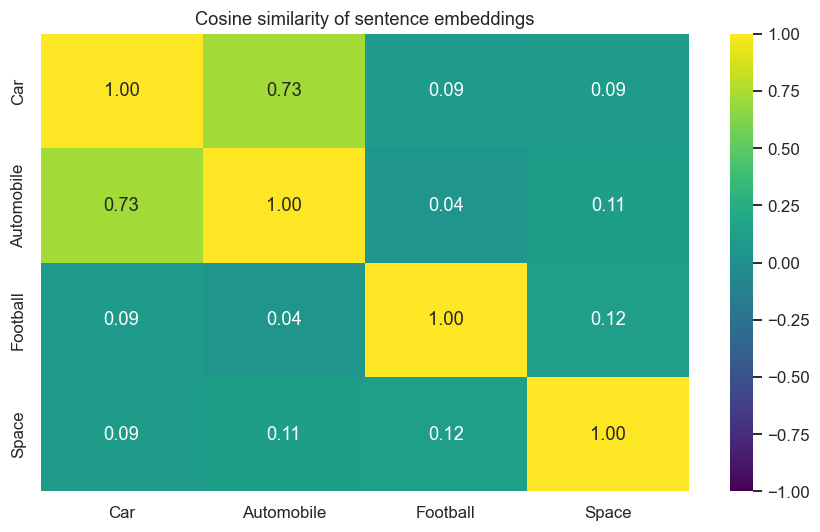

In [45]:
# EXAMPLE: cosine similarity between embeddings of similar/dissimilar semantic sentences
example_texts = ['The car needs repairs.', 'The automobile requires maintenance.',
                 'The team won the football match.', 'A spacecraft entered orbit.']
example_vectors = encoder.encode(example_texts, normalize_embeddings=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cosine_similarity(example_vectors), annot=True, fmt='.2f',
            xticklabels=['Car', 'Automobile', 'Football', 'Space'],
            yticklabels=['Car', 'Automobile', 'Football', 'Space'],
            cmap='viridis', vmin=-1, vmax=1, ax=ax)
ax.set_title('Cosine similarity of sentence embeddings')
plt.tight_layout(); plt.show()

## 3. Manual pipeline: UMAP and HDBSCAN

UMAP maps the 384-dimensional vectors to **five dimensions for clustering**. A separate two-dimensional map will be used only for display.

### UMAP: parameters

In [46]:
# UMAP: reduce the document embeddings before clustering.
BASE_UMAP = dict(
    n_neighbors=15,       # Neighborhood size used to construct the graph.
                          # Smaller values emphasize local detail; larger values
                          # incorporate broader relationships.

    n_components=5,       # Reduce each document embedding to 5 dimensions.
                          # These coordinates are used for clustering, not plotting.

    min_dist=0.0,         # allows UMAP to place neighboring points very close together 
                          # in the low-dimensional space, producing compact groups.
                          # This is not a hard minimum-distance constraint.

    metric='cosine',      # Use cosine distance to identify neighbors in the
                          # original document-embedding space.

    random_state=SEED,    # Fix the random seed for reproducible results
                          # within the same software/environment configuration.

    n_jobs=1              # Use one parallel worker.
)
manual_umap = UMAP(**BASE_UMAP)
reduced = manual_umap.fit_transform(embeddings)

### HDBSCAN: parameters


Importan HDBSCAN parameters:
- `min_samples` controls local density sensitivity; 
- `min_cluster_size` controls the smallest retained branch. We set both explicitly so changing one does not silently change the other.

In [65]:
# HDBSCAN: cluster the reduced document embeddings.
BASE_HDBSCAN = dict(
    min_cluster_size=80, # Minimum size of a group retained as a candidate cluster
                         # when condensing the hierarchy.

    min_samples=10,      # Neighborhood size used to compute core distances.
                         # Larger values generally make clustering more conservative,
                         # often increasing the number of noise points.
                         # Set explicitly so it does not default to min_cluster_size.

    metric='euclidean',  # Measure distances in the 5-dimensional UMAP space.

    cluster_selection_method='leaf',    # eom: Excess of Mass: select branches by comparing their
                                        # stability with the combined stability of descendants.
                                        # 'leaf' tells HDBSCAN to select the terminal clusters, i.e.,
                                        #the leaves—of its condensed hierarchy. 
                                        # These are clusters that do not split further 
                                        # into subclusters meeting min_cluster_size.

    prediction_data=True, # Store additional information for approximate assignment
                          # of new points and supported soft-membership calculations.
                          # This does not itself assign any new points.

    gen_min_span_tree=True # Retain the minimum spanning tree so it can be inspected
                           # or plotted through minimum_spanning_tree_.
)
manual_clusterer = HDBSCAN(**BASE_HDBSCAN)
manual_labels = manual_clusterer.fit_predict(reduced)

print('Reduced matrix:', reduced.shape)
print('Clusters:', len(set(manual_labels) - {-1}))
print('Outlier fraction:', np.mean(manual_labels == -1))

Reduced matrix: (1800, 5)
Clusters: 6
Outlier fraction: 0.14888888888888888


### A fixed map for all comparisons
We fit the display map once and reuse it. Colors can change when assignments change, while point positions stay fixed. The map itself is not proof of separation or topic quality.

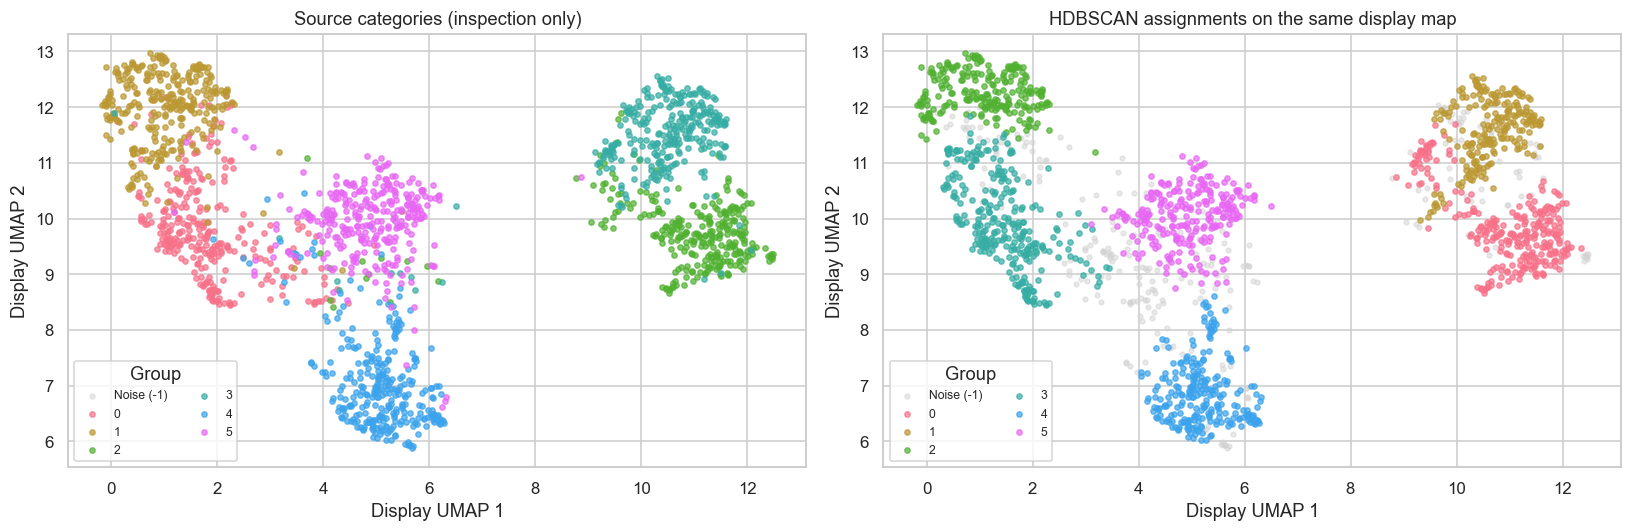

,code,category
0,0,comp.graphics
1,1,comp.sys.mac.hardware
2,2,rec.sport.baseball
3,3,rec.sport.hockey
4,4,sci.med
5,5,sci.space


In [66]:
display_xy = UMAP(n_neighbors=30, n_components=2, min_dist=0.15,
                  metric='cosine', random_state=SEED, n_jobs=1).fit_transform(embeddings)

def plot_assignments(labels, title, ax=None):
    labels = np.asarray(labels)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    noise = labels == -1
    ax.scatter(display_xy[noise, 0], display_xy[noise, 1], c='lightgray',
               s=10, alpha=.5, label='Noise (-1)')
    ids = sorted(set(labels) - {-1})
    colors = sns.color_palette('husl', max(1, len(ids)))
    for c, color in zip(ids, colors):
        mask = labels == c
        ax.scatter(display_xy[mask, 0], display_xy[mask, 1], s=12,
                   color=color, alpha=.7, label=str(c))
    ax.set(title=title, xlabel='Display UMAP 1', ylabel='Display UMAP 2')
    if len(ids) <= 12:
        ax.legend(title='Group', fontsize=8, ncol=2, loc='best')
    return ax

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
reference_codes, reference_names = pd.factorize(y_reference, sort=True)
plot_assignments(reference_codes, 'Source categories (inspection only)', axes[0])
plot_assignments(manual_labels, 'HDBSCAN assignments on the same display map', axes[1])
plt.tight_layout(); plt.show()
display(pd.DataFrame({'code': range(len(reference_names)), 'category': reference_names}))

On the left we display the simplified hierarchy after applying min_cluster_size=80.

- **Vertical axis**: $\lambda=1/\varepsilon$. Moving toward larger $\lambda$ imposes stricter connectivity requirements. In this plot, $\lambda$ increases downward.
- **Branches**: candidate clusters that persist, lose points, or split.
- **Branch width/color**: indicates the number of points remaining in a branch.
- **Highlighted branches**: the clusters selected by the EOM stability criterion.

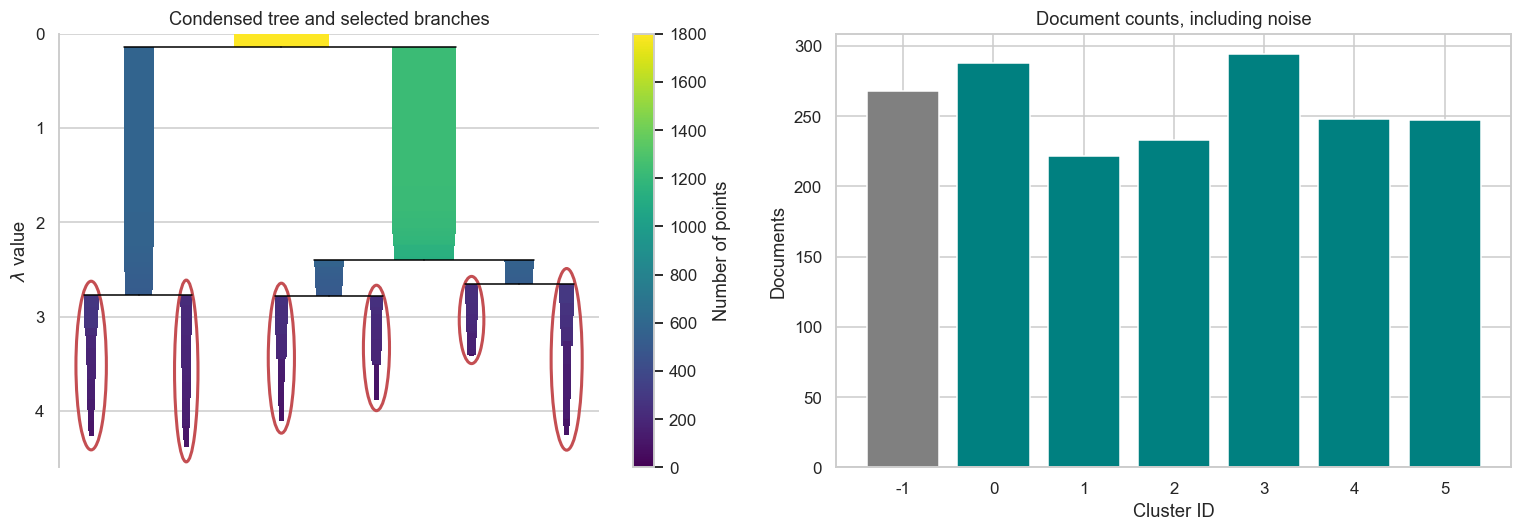

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
manual_clusterer.condensed_tree_.plot(select_clusters=True, axis=axes[0])
axes[0].set_title('Condensed tree and selected branches')

sizes = pd.Series(manual_labels).value_counts().sort_index()
axes[1].bar(sizes.index.astype(str), sizes.values, color=['gray' if i == -1 else 'teal' for i in sizes.index])
axes[1].set(title='Document counts, including noise', xlabel='Cluster ID', ylabel='Documents')

plt.tight_layout(); 
plt.show()

## 4. Manual c-TF-IDF
Combine original texts by cluster, tokenize the aggregated texts, and obtain a sparse count matrix.

For term $t$ and aggregated group $c$:
$$w_{t,c}=\frac{n_{t,c}}{N_c}\log(1+A/f_t),\qquad
N_c=\sum_t n_{t,c},\quad f_t=\sum_c n_{t,c}.$$

$A$ is the average row total. The default BERTopic implementation converts that mean to an integer; 

For comparability, the `-1` documents form an aggregated **noise row** if present. That row participates in the corpus-wide statistics but must not be interpreted as one coherent topic. 

In [50]:
# Combine the original documents belonging to each cluster.
documents = pd.DataFrame({'text': docs, 'topic': manual_labels})
grouped_docs = documents.groupby('topic', sort=True)['text'].agg(' '.join)

# Build a cluster–term count matrix, excluding English stopwords.
vectorizer_model = CountVectorizer(stop_words='english')
counts = vectorizer_model.fit_transform(grouped_docs)

# Column names of the count matrix.
words = vectorizer_model.get_feature_names_out()

print('Cluster–term matrix:', counts.shape)

Cluster–term matrix: (7, 26752)


In [51]:
from bertopic.vectorizers import ClassTfidfTransformer

# Weight terms according to their frequency within and across clusters.
ctfidf_model = ClassTfidfTransformer()
ctfidf = ctfidf_model.fit_transform(counts)

### Display the top words for each topic

In [52]:
top_n = 10
topic_rows = []

for row, topic in enumerate(grouped_docs.index):
    if topic == -1:
        continue  # Do not present the noise group as a topic.

    # Convert only this topic's score vector to a dense array.
    scores = ctfidf.getrow(row).toarray().ravel()

    # Select the highest-scoring terms with positive weights.
    top_indices = scores.argsort()[::-1][:top_n]
    top_indices = top_indices[scores[top_indices] > 0]

    topic_rows.append({
        'topic': topic,
        'documents': (documents.topic == topic).sum(),
        'keywords': ', '.join(words[top_indices])
    })

topic_table = pd.DataFrame(
    topic_rows, columns=['topic', 'documents', 'keywords']
)
display(topic_table)

,topic,documents,keywords
0,0,288,"year, game, games, team, baseball, pts, la, th..."
1,1,222,"25, team, 14, 10, game, play, 12, 13, 11, 15"
2,2,233,"mac, apple, drive, scsi, bit, 32, memory, ram,..."
3,3,294,"image, graphics, use, program, file, files, da..."
4,4,248,"medical, cancer, people, patients, hiv, health..."
5,5,247,"space, nasa, launch, satellite, orbit, shuttle..."


### Inspect one topic: keywords and documents


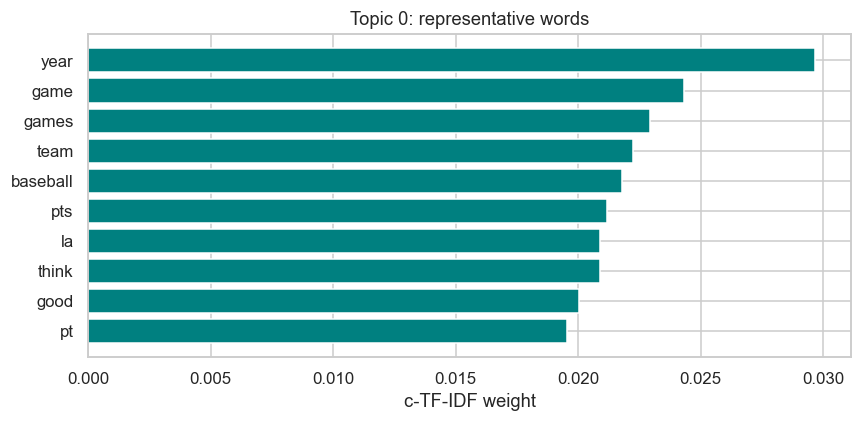

It was my impression watching the Mets & Rockies that umpires were calling strikes above the belt, too, but not as far up as the letters. It would be nice if this were the case. 

Let's see... April 15th... less than 30 at bats.... and you claim that he hasn't done too much so far! Cut this guy some slack. Danny will produce this year. It's scary to think just how much he'll produce if he were to stay healthy all year. The Yanks have a lot going for them this year: good starting rotation, good bullpen, good defense and a good lineup. Also, I like Buck Showalter. Frank Howard on 1st is also a good move. Everything sounds good so far. If the Yanks stay healthy, they have a good chance at winning the pennant. This is the most fun I've had watching the Yanks since "78! 

One "t" in "Eddie Mathews"! Because a small advantage in fielding ability comes nowhere near making up for the large difference in hitting. Their average seasons, using their combined average 656 (AB + BB) per 162 games: Y

In [53]:
# Choose a topic ID from the table above.
topic_id = 0

# Locate its row in the c-TF-IDF matrix.
row = grouped_docs.index.get_loc(topic_id)
scores = ctfidf.getrow(row).toarray().ravel()
top_indices = scores.argsort()[::-1][:10]
top_indices = top_indices[scores[top_indices] > 0]

# Plot its representative words.
plt.figure(figsize=(8, 4))
plt.barh(words[top_indices][::-1], scores[top_indices][::-1], color='teal')
plt.xlabel('c-TF-IDF weight')
plt.title(f'Topic {topic_id}: representative words')
plt.tight_layout()
plt.show()

# Read a few documents to check whether the description fits.
members = documents.loc[documents.topic == topic_id, 'text']
for text in members.sample(n=min(3, len(members)), random_state=SEED):
    print(text[:800], '\n')

## 5. The same pipeline with BERTopic
We now use BERTopic as the orchestrator. No document encoder is retrained.

BERTopic can renumber clusters by size, so numeric equality of labels is the wrong comparison.

In [54]:
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer


topic_model = BERTopic(embedding_model=encoder,
                    umap_model=UMAP(**BASE_UMAP),
                    hdbscan_model=HDBSCAN(**BASE_HDBSCAN),
                    vectorizer_model=CountVectorizer(stop_words='english'),
                    ctfidf_model=ClassTfidfTransformer(),
                    calculate_probabilities=False, # Skip the full document-by-topic membership matrix,
                                                   # saving computation and memory.
                                                   # HDBSCAN can still return a membership-strength
                                                   # score for each document's assigned cluster.
                    verbose=True)

bt_topics, bt_strengths = topic_model.fit_transform(docs, embeddings=embeddings)
bt_topics = np.asarray(bt_topics)

display(topic_model.get_topic_info())
display(topic_model.get_document_info(docs).head())

2026-10-28 19:34:18,006 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-28 19:34:21,230 - BERTopic - Dimensionality - Completed ✓
2026-10-28 19:34:21,230 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-28 19:34:21,246 - BERTopic - Cluster - Completed ✓
2026-10-28 19:34:21,247 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-28 19:34:21,341 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,268,-1_edu_hockey_water_new,"[edu, hockey, water, new, like, nhl, league, t...",[Archive-name: typing-injury-faq/general Versi...
1,0,294,0_image_graphics_use_program,"[image, graphics, use, program, file, files, d...",[**************************** SPHINX *********...
2,1,288,1_year_game_games_team,"[year, game, games, team, baseball, pts, la, t...","[MLB Standings and Scores for Friday, April 16..."
3,2,248,2_medical_cancer_people_patients,"[medical, cancer, people, patients, hiv, healt...",[------------- cut here ----------------- HICN...
4,3,247,3_space_nasa_launch_satellite,"[space, nasa, launch, satellite, orbit, shuttl...",[Archive-name: space/acronyms Edition: 8 Acron...
5,4,233,4_mac_apple_drive_scsi,"[mac, apple, drive, scsi, bit, 32, memory, ram...","[: : Excuse me if this is a frequent question,..."
6,5,222,5_25_team_14_10,"[25, team, 14, 10, game, play, 12, 13, 11, 15]",[The FLYERS closed out the season last night w...


,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Probability,Representative_document
0,"ETHER IMPLODES 2 EARTH CORE, IS GRAVITY!!! Thi...",-1,-1_edu_hockey_water_new,"[edu, hockey, water, new, like, nhl, league, t...",[Archive-name: typing-injury-faq/general Versi...,edu - hockey - water - new - like - nhl - leag...,0.000000,False
1,I was watching the Detroit-Minnesota game last...,-1,-1_edu_hockey_water_new,"[edu, hockey, water, new, like, nhl, league, t...",[Archive-name: typing-injury-faq/general Versi...,edu - hockey - water - new - like - nhl - leag...,0.000000,False
2,Mr. Hernandez Ñ- I apologize for the misunders...,5,5_25_team_14_10,"[25, team, 14, 10, game, play, 12, 13, 11, 15]",[The FLYERS closed out the season last night w...,25 - team - 14 - 10 - game - play - 12 - 13 - ...,0.941082,False
3,I've got an old demo disk that I need to view....,0,0_image_graphics_use_program,"[image, graphics, use, program, file, files, d...",[**************************** SPHINX *********...,image - graphics - use - program - file - file...,1.000000,False
4,"For a brief, but pretty detailed account, try ...",2,2_medical_cancer_people_patients,"[medical, cancer, people, patients, hiv, healt...",[------------- cut here ----------------- HICN...,medical - cancer - people - patients - hiv - h...,0.776942,False


### Interactive BERTopic plots
Use the fixed 2D display coordinates for the document map. Hover to inspect texts. Keyword bar charts show representation scores; they do not show probabilities.

In [55]:
n_bt_topics = len(set(bt_topics)-{-1})
if n_bt_topics:
    topic_model.visualize_barchart(top_n_topics=min(6, n_bt_topics), n_words=8).show()
    topic_model.visualize_documents(docs, reduced_embeddings=display_xy,
                                    hide_annotations=True).show()
else:
    print('No non-noise topics: revisit the clustering settings.')
if n_bt_topics >= 2:
    topic_model.visualize_heatmap().show()

## 8. Optional: refine keywords with KeyBERTInspired
This representation model uses semantic information to refine topic keywords. It changes descriptions, while keeping the discovered groups fixed. Compare the words and check supporting texts; more fluent labels alone do not prove better clusters.

In [56]:
from bertopic.representation import KeyBERTInspired

# Proceed if at least one non-noise topic exists.
if n_bt_topics:

    # Create an independent copy to preserve the original topic descriptions.
    refined_model = copy.deepcopy(topic_model)

    # Recalculate topic descriptions using:
    # - Single words and two-word phrases as candidate terms.
    # - KeyBERTInspired to refine keywords using embedding similarity
    #   between candidate terms and a representation of representative documents.
    # Existing document-to-topic assignments remain unchanged.
    refined_model.update_topics(
        docs,
        representation_model=KeyBERTInspired(),
        vectorizer_model=CountVectorizer(
            stop_words='english',  # Exclude common English stopwords.
            ngram_range=(1, 2)     # Include unigrams and bigrams.
        )
    )


    # Select up to six topic IDs, excluding the noise label (-1).
    ids = sorted(set(bt_topics) - {-1})[:6]

    # Compare the first eight keywords/phrases from each model.
    # get_topic(t) returns (term, score) pairs; we display only the terms.
    for t in ids:
        baseline = ', '.join(w for w, _ in topic_model.get_topic(t)[:8])
        refined = ', '.join(w for w, _ in refined_model.get_topic(t)[:8])

        print(f"Topic {t}")
        print(f"  Baseline: {baseline}")
        print(f"  Refined:  {refined}")
        print("-" * 80)

Topic 0
  Baseline: image, graphics, use, program, file, files, data, software
  Refined:  graphics, image processing, software, images, tools, program, 3d, jpeg
--------------------------------------------------------------------------------
Topic 1
  Baseline: year, game, games, team, baseball, pts, la, think
  Refined:  braves, cubs, phillies, suck cubs, cubs suck, sox, hitter, pitching
--------------------------------------------------------------------------------
Topic 2
  Baseline: medical, cancer, people, patients, hiv, health, pain, msg
  Refined:  medical newsletter, medicine, patients, clinical, medical, diseases, disease, health
--------------------------------------------------------------------------------
Topic 3
  Baseline: space, nasa, launch, satellite, orbit, shuttle, lunar, mission
  Refined:  nasa, sci space, nasa gov, spacecraft, space shuttle, astro, astronomy, space
--------------------------------------------------------------------------------
Topic 4
  Baseli